In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df=pd.read_csv("ecommerce_customer_behavior_dataset.csv")

In [4]:
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())
print("\nFirst 5 rows:")
display(df.head())

Dataset shape: (5000, 18)

Column names:
['Order_ID', 'Customer_ID', 'Date', 'Age', 'Gender', 'City', 'Product_Category', 'Unit_Price', 'Quantity', 'Discount_Amount', 'Total_Amount', 'Payment_Method', 'Device_Type', 'Session_Duration_Minutes', 'Pages_Viewed', 'Is_Returning_Customer', 'Delivery_Time_Days', 'Customer_Rating']

First 5 rows:


,Order_ID,Customer_ID,Date,Age,Gender,City,Product_Category,Unit_Price,Quantity,Discount_Amount,Total_Amount,Payment_Method,Device_Type,Session_Duration_Minutes,Pages_Viewed,Is_Returning_Customer,Delivery_Time_Days,Customer_Rating
0,ORD_001337,CUST_01337,2023-01-01,27,Female,Bursa,Toys,54.28,1,0.00,54.28,Debit Card,Mobile,4,14,True,8,5
1,ORD_004885,CUST_04885,2023-01-01,42,Male,Konya,Toys,244.90,1,0.00,244.90,Credit Card,Mobile,11,3,True,3,3
2,ORD_004507,CUST_04507,2023-01-01,43,Female,Ankara,Food,48.15,5,0.00,240.75,Credit Card,Mobile,7,8,True,5,2
3,ORD_000645,CUST_00645,2023-01-01,32,Male,Istanbul,Electronics,804.06,1,229.28,574.78,Credit Card,Mobile,8,10,False,1,4
4,ORD_000690,CUST_00690,2023-01-01,40,Female,Istanbul,Sports,755.61,5,0.00,3778.05,Cash on Delivery,Desktop,21,10,True,7,4


In [5]:
print("Missing values in each column:")
print(df.isnull().sum())
print("\nNumber of duplicate rows:", df.duplicated().sum())


Missing values in each column:
Order_ID                    0
Customer_ID                 0
Date                        0
Age                         0
Gender                      0
City                        0
Product_Category            0
Unit_Price                  0
Quantity                    0
Discount_Amount             0
Total_Amount                0
Payment_Method              0
Device_Type                 0
Session_Duration_Minutes    0
Pages_Viewed                0
Is_Returning_Customer       0
Delivery_Time_Days          0
Customer_Rating             0
dtype: int64

Number of duplicate rows: 0


In [6]:
df['Date'] = pd.to_datetime(df['Date'], errors='coerce')
print("Date column data type:", df['Date'].dtype)
print("Invalid dates:", df['Date'].isna().sum())
print("Earliest transaction:", df['Date'].min())
print("Latest transaction:", df['Date'].max())

Date column data type: datetime64[ns]
Invalid dates: 0
Earliest transaction: 2023-01-01 00:00:00
Latest transaction: 2024-03-26 00:00:00


In [7]:
print("Customer Age Statistics:")
print(df['Age'].describe())
print("\nTransaction Amount Statistics:")
print(df['Total_Amount'].describe())
print("\nCustomers with age below 0 or above 100:",
      ((df['Age'] < 0) | (df['Age'] > 100)).sum())
print("Transactions with negative amounts:",
      (df['Total_Amount'] < 0).sum())
print("Transactions with zero amounts:",
      (df['Total_Amount'] == 0).sum())

Customer Age Statistics:
count    5000.000000
mean       35.032600
std        11.080546
min        18.000000
25%        27.000000
50%        35.000000
75%        42.000000
max        75.000000
Name: Age, dtype: float64

Transaction Amount Statistics:
count     5000.000000
mean       983.108914
std       1898.978528
min          7.870000
25%        122.517500
50%        337.910000
75%        979.695000
max      22023.900000
Name: Total_Amount, dtype: float64

Customers with age below 0 or above 100: 0
Transactions with negative amounts: 0
Transactions with zero amounts: 0


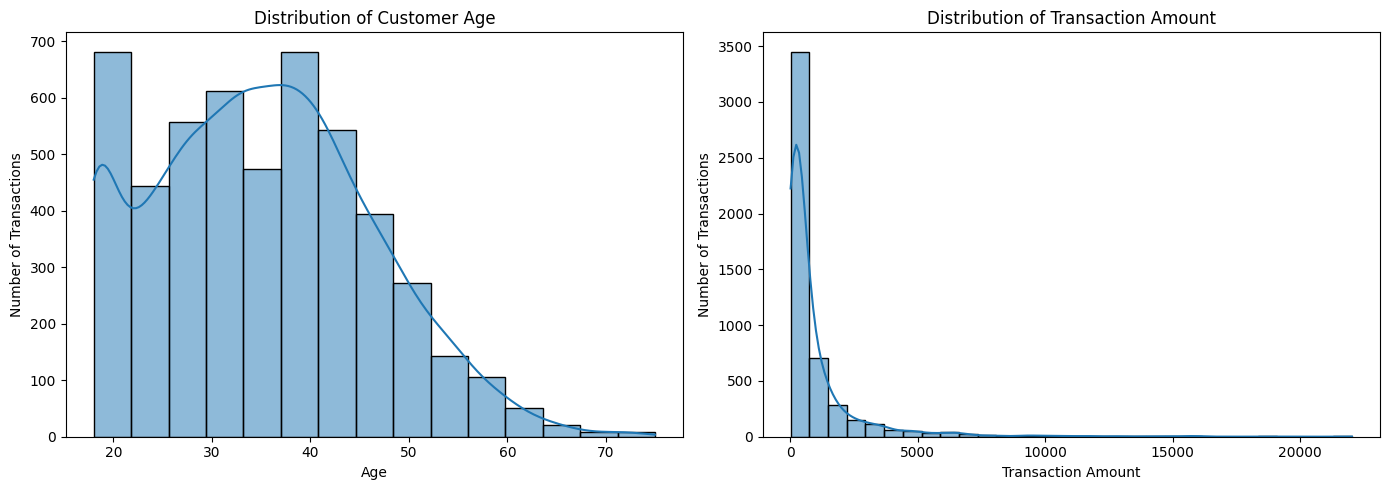

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(data=df, x='Age', bins=15, kde=True, ax=axes[0])
axes[0].set_title('Distribution of Customer Age')
axes[0].set_xlabel('Age')
axes[0].set_ylabel('Number of Transactions')
sns.histplot(data=df, x='Total_Amount', bins=30, kde=True, ax=axes[1])
axes[1].set_title('Distribution of Transaction Amount')
axes[1].set_xlabel('Transaction Amount')
axes[1].set_ylabel('Number of Transactions')
plt.tight_layout()
plt.show()

Monthly Sales:


,Total_Amount
Date,
2023-01-31,286694.32
2023-02-28,338784.92
2023-03-31,321716.01
2023-04-30,257332.58
2023-05-31,351902.03
2023-06-30,324356.96
2023-07-31,346618.03
2023-08-31,391505.89
2023-09-30,262602.86


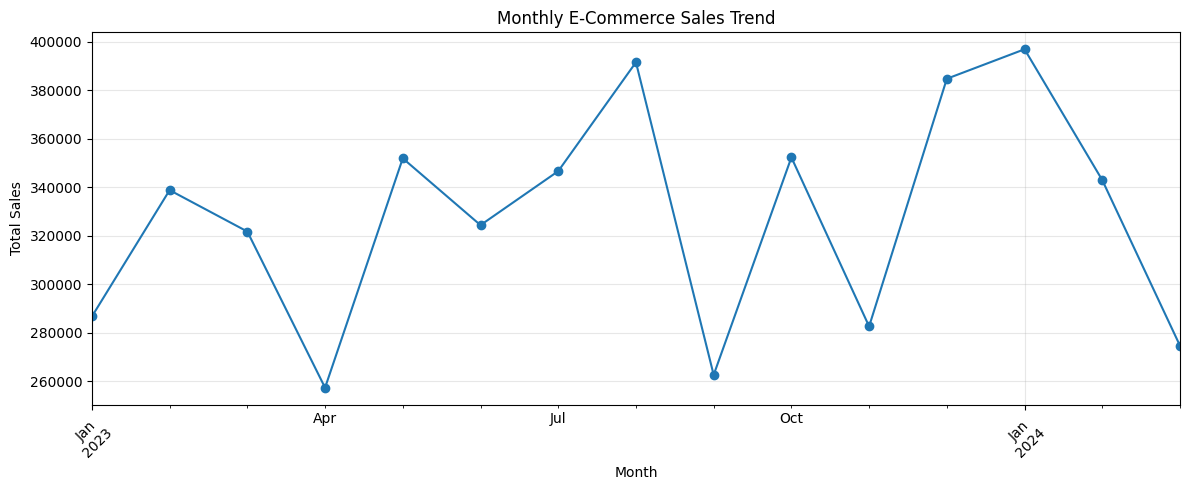

In [9]:
monthly_sales = (df.set_index('Date')['Total_Amount'].resample('ME').sum())
print("Monthly Sales:")
display(monthly_sales)
plt.figure(figsize=(12, 5))
monthly_sales.plot(marker='o')
plt.title('Monthly E-Commerce Sales Trend')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [10]:
print("Total transactions:", len(df))
print("Unique customers:", df['Customer_ID'].nunique())
print("Unique order IDs:", df['Order_ID'].nunique())
print("\nRows per order (first 10 order IDs):")
display(df.groupby('Order_ID').size().head(10))

Total transactions: 5000
Unique customers: 5000
Unique order IDs: 5000

Rows per order (first 10 order IDs):


,0
Order_ID,
ORD_000001,1
ORD_000002,1
ORD_000003,1
ORD_000004,1
ORD_000005,1
ORD_000006,1
ORD_000007,1
ORD_000008,1
ORD_000009,1


In [13]:
customer_frequency = df.groupby("Customer_ID")["Order_ID"].nunique()
print("Total customers:", df["Customer_ID"].nunique())
print("Customers with more than one order:",
      (customer_frequency > 1).sum())
print("\nReturning-customer flag:")
print(df["Is_Returning_Customer"].value_counts())

print("\nSample customer purchase frequency:")
print(customer_frequency.value_counts().sort_index())

Total customers: 5000
Customers with more than one order: 0

Returning-customer flag:
Is_Returning_Customer
True     2990
False    2010
Name: count, dtype: int64

Sample customer purchase frequency:
Order_ID
1    5000
Name: count, dtype: int64


In [14]:
df["Date"] = pd.to_datetime(df["Date"])
snapshot_date = df["Date"].max() + pd.Timedelta(days=1)
rfm = df.groupby("Customer_ID").agg(
    Recency=("Date", lambda x: (snapshot_date - x.max()).days),
    Frequency=("Order_ID", "nunique"),
    Monetary=("Total_Amount", "sum"))
print("RFM Dataset Shape:", rfm.shape)
display(rfm.head(10))

RFM Dataset Shape: (5000, 3)


,Recency,Frequency,Monetary
Customer_ID,,,
CUST_00001,124,1,219.32
CUST_00002,394,1,332.34
CUST_00003,439,1,66.44
CUST_00004,72,1,112.65
CUST_00005,311,1,349.45
CUST_00006,326,1,131.96
CUST_00007,337,1,150.41
CUST_00008,380,1,49.10
CUST_00009,74,1,55.89


In [15]:
rfm["R_Score"] = pd.qcut(
    rfm["Recency"].rank(method="first"),
    4,
    labels=[4, 3, 2, 1]).astype(int)
rfm["M_Score"] = pd.qcut(
    rfm["Monetary"].rank(method="first"),
    4,
    labels=[1, 2, 3, 4]).astype(int)
rfm["RFM_Score"] = rfm["R_Score"] + rfm["M_Score"]
print("RFM scoring completed!")
display(rfm.head(10))

RFM scoring completed!


,Recency,Frequency,Monetary,R_Score,M_Score,RFM_Score
Customer_ID,,,,,,
CUST_00001,124,1,219.32,3,2,5
CUST_00002,394,1,332.34,1,2,3
CUST_00003,439,1,66.44,1,1,2
CUST_00004,72,1,112.65,4,1,5
CUST_00005,311,1,349.45,2,3,5
CUST_00006,326,1,131.96,2,2,4
CUST_00007,337,1,150.41,1,2,3
CUST_00008,380,1,49.10,1,1,2
CUST_00009,74,1,55.89,4,1,5


In [16]:
def assign_segment(row):
    if row["R_Score"] >= 3 and row["M_Score"] >= 3:
        return "High Value"
    elif row["R_Score"] >= 3 or row["M_Score"] >= 3:
        return "Potential"
    elif row["R_Score"] <= 2 and row["M_Score"] <= 2:
        return "At Risk"
    else:
        return "Needs Attention"

rfm["Customer_Segment"] = rfm.apply(assign_segment, axis=1)

print("Customer segmentation completed!")

print("\nCustomers in each segment:")
print(rfm["Customer_Segment"].value_counts())

print("\nSample segmented customers:")
display(rfm.head(10))

Customer segmentation completed!

Customers in each segment:
Customer_Segment
Potential     2506
At Risk       1247
High Value    1247
Name: count, dtype: int64

Sample segmented customers:


,Recency,Frequency,Monetary,R_Score,M_Score,RFM_Score,Customer_Segment
Customer_ID,,,,,,,
CUST_00001,124,1,219.32,3,2,5,Potential
CUST_00002,394,1,332.34,1,2,3,At Risk
CUST_00003,439,1,66.44,1,1,2,At Risk
CUST_00004,72,1,112.65,4,1,5,Potential
CUST_00005,311,1,349.45,2,3,5,Potential
CUST_00006,326,1,131.96,2,2,4,At Risk
CUST_00007,337,1,150.41,1,2,3,At Risk
CUST_00008,380,1,49.10,1,1,2,At Risk
CUST_00009,74,1,55.89,4,1,5,Potential


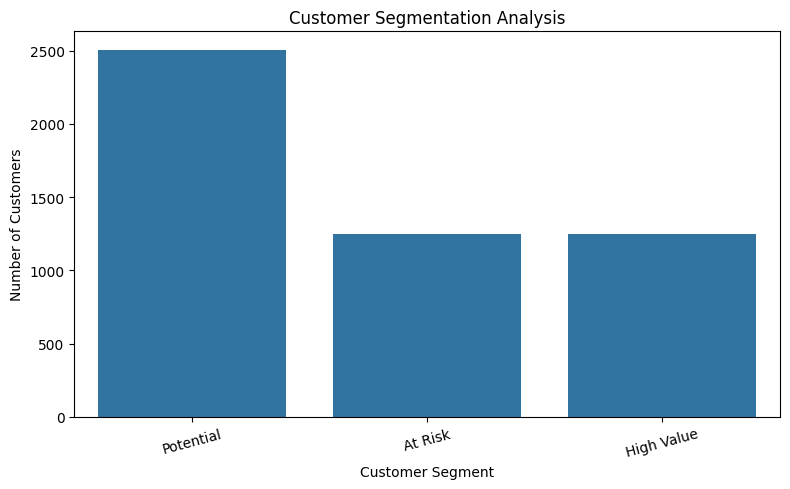

In [17]:
segment_counts = rfm["Customer_Segment"].value_counts()
plt.figure(figsize=(8, 5))
sns.barplot(
    x=segment_counts.index,
    y=segment_counts.values)
plt.title("Customer Segmentation Analysis")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

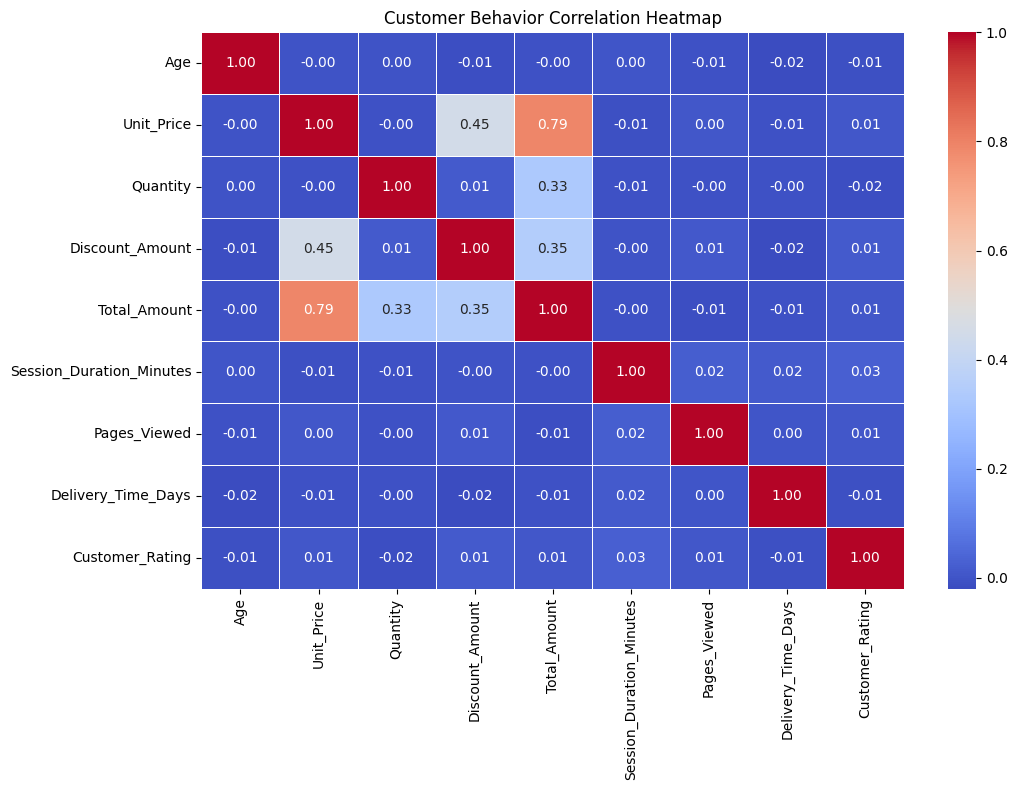

In [18]:
numeric_cols = [
    "Age",
    "Unit_Price",
    "Quantity",
    "Discount_Amount",
    "Total_Amount",
    "Session_Duration_Minutes",
    "Pages_Viewed",
    "Delivery_Time_Days",
    "Customer_Rating"
]

correlation = df[numeric_cols].corr()

plt.figure(figsize=(11, 8))
sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)
plt.title("Customer Behavior Correlation Heatmap")
plt.tight_layout()
plt.show()

In [19]:
customer_spending = rfm["Monetary"].sort_values(ascending=False).reset_index()
customer_spending["Cumulative_Revenue"] = (
    customer_spending["Monetary"].cumsum()
    / customer_spending["Monetary"].sum()) * 100
customer_spending["Cumulative_Customers"] = (
    (customer_spending.index + 1)
    / len(customer_spending)) * 100
top_20_count = int(len(customer_spending) * 0.20)

top_20_revenue = (
    customer_spending.head(top_20_count)["Monetary"].sum()
    / customer_spending["Monetary"].sum()
) * 100
print(f"Total customers: {len(customer_spending)}")
print(f"Total revenue: {customer_spending['Monetary'].sum():,.2f}")
print(f"Top 20% of customers: {top_20_count}")
print(f"Revenue contributed by top 20%: {top_20_revenue:.2f}%")

Total customers: 5000
Total revenue: 4,915,544.57
Top 20% of customers: 1000
Revenue contributed by top 20%: 72.04%


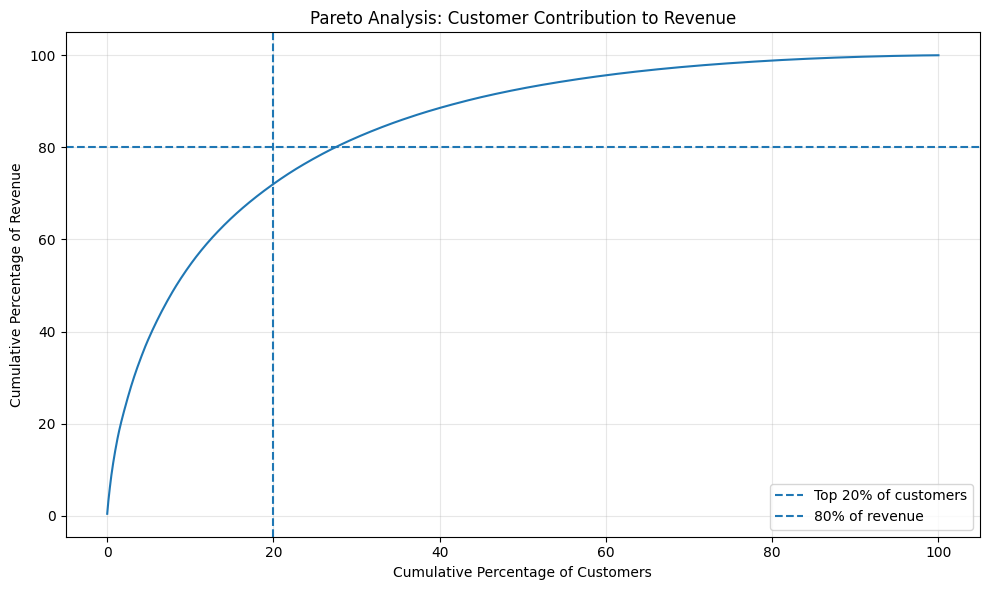

In [20]:
plt.figure(figsize=(10, 6))
plt.plot(customer_spending["Cumulative_Customers"],customer_spending["Cumulative_Revenue"])
plt.axvline(20, linestyle="--", label="Top 20% of customers")
plt.axhline(80, linestyle="--", label="80% of revenue")
plt.title("Pareto Analysis: Customer Contribution to Revenue")
plt.xlabel("Cumulative Percentage of Customers")
plt.ylabel("Cumulative Percentage of Revenue")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [21]:
monthly_sales = df.set_index("Date")["Total_Amount"].resample("ME").sum()
print("Highest sales month:")
print(monthly_sales.idxmax().strftime("%B %Y"))
print(f"Sales: {monthly_sales.max():,.2f}")
print("\nLowest sales month:")
print(monthly_sales.idxmin().strftime("%B %Y"))
print(f"Sales: {monthly_sales.min():,.2f}")
print(f"\nAverage monthly sales: {monthly_sales.mean():,.2f}")

Highest sales month:
January 2024
Sales: 396,874.92

Lowest sales month:
April 2023
Sales: 257,332.58

Average monthly sales: 327,702.97


In [22]:
category_sales = df.groupby("Product_Category")["Total_Amount"].sum().sort_values(ascending=False)
print("SALES BY PRODUCT CATEGORY")
display(category_sales.to_frame("Total_Sales"))
print("Top-selling category by revenue:", category_sales.idxmax())
payment_counts = df["Payment_Method"].value_counts()
print("\nPAYMENT METHOD USAGE")
display(payment_counts.to_frame("Number_of_Orders"))
print("Most commonly used payment method:", payment_counts.idxmax())
print("\nRETURNING CUSTOMER FLAG")
display(df["Is_Returning_Customer"].value_counts().to_frame("Number_of_Orders"))

SALES BY PRODUCT CATEGORY


,Total_Sales
Product_Category,
Electronics,2328806.81
Home & Garden,908348.86
Sports,754563.56
Fashion,375214.93
Toys,223142.48
Beauty,156584.74
Food,96138.67
Books,72744.52


Top-selling category by revenue: Electronics

PAYMENT METHOD USAGE


,Number_of_Orders
Payment_Method,
Credit Card,2012
Debit Card,1265
Digital Wallet,965
Bank Transfer,510
Cash on Delivery,248


Most commonly used payment method: Credit Card

RETURNING CUSTOMER FLAG


,Number_of_Orders
Is_Returning_Customer,
True,2990
False,2010


## Conclusion

The E-Commerce Customer Behavior Analysis project explored sales trends, product performance, customer spending patterns, and purchasing behavior using Python, Pandas, Matplotlib, and Seaborn. The dataset contained 5,000 transactions with total revenue of 4,915,544.57.

Electronics generated the highest revenue, while January 2024 recorded the highest monthly sales. Credit cards were the most frequently used payment method. The top 20% of customers contributed 72.04% of total revenue, indicating that revenue was concentrated among higher-spending customers.

Customer segmentation based on purchase recency and monetary value identified High Value, Potential, and At Risk groups. However, because each customer had only one recorded transaction, repeat-purchase frequency and actual churn risk could not be established independently.

Overall, the project demonstrates how exploratory data analysis and visualization can support data-driven business decisions, identify revenue opportunities, and guide future customer-retention strategies.
